# Fitting RealNVP and cRealNVP to pdf values instead of samples

In [realnvp_crealnvp_distribution_fitting.ipynb](realnvp_crealnvp_distribution_fitting.ipynb) the flows learn from
**samples** `x ~ p`. Often the distribution function itself is known, either analytically or as a table, while
samples are not readily available. A flow can then be trained **directly on pdf values**.

**Idea (weighted forward KL).** Maximum likelihood minimizes the cross entropy `H(p, q) = -∫ p(x) log q(x) dx`.
With samples this integral is estimated as `-mean(log q(x_i))`, `x_i ~ p`. If `p` can be evaluated, the integral is estimated
at arbitrary points `x_i ~ r` instead (a grid, uniform points in a box, or any proposal):

```
H(p, q)  ≈  -1/N Σ_i  w_i · log q(x_i),        w_i ∝ p(x_i) / r(x_i),   mean(w_i) = 1
```

- The normalization of `p` cancels, so an **unnormalized** `p̃` is enough.
- No sampling noise from `p`: on a fixed grid the loss is a deterministic quadrature.
- The loss estimates `H(p, q) = KL(p ‖ q) + H(p)`, so its minimum is the entropy of the target (a built-in check).
- Like sample-based training it is **mass covering**: regions with `p > 0` are penalized if `q` misses them.

**Usage.** `fit_model` gets the points as `x` (and `cond`) and the target as `pdf=` or `log_pdf=`.
If the points are not placed uniformly, `log_proposal=` gives `log r(x_i)`:

```python
fit_model(flow,  x_points,          log_pdf=log_p(x_points))                       # uniform grid / box
fit_model(flow,  x_points,          log_pdf=log_p(x_points), log_proposal=log_r)   # importance sampling
fit_model(cflow, x_points, c_points, log_pdf=log_p(x_points, c_points))           # conditional p(x | c)
```

| Section | Model | Target distribution | Points |
|---|---|---|---|
| 3 | RealNVP | 2D Gaussian mixture `p(x)` | regular grid |
| 4 | RealNVP | samples vs. pdf values for different numbers of points | samples / grid |
| 5 | RealNVP | 3D Gaussian velocity distribution `p(v)` (Maxwell magnitude) | uniform box vs. importance sampling |
| 6 | cRealNVP | Maxwell distribution with temperature as condition `p(v \| T)` | box scaled with `√T` |
| 7 | RealNVP | unnormalized, tabulated ring distribution | table on a grid |

Units: `m = k_B = 1`, so `σ² = T` and `v ~ N(0, T·I)`.

> **Disclaimer:** The models in this notebook are illustrative examples, not optimized results. Architectures, hyperparameters and training settings were chosen to keep the runtime short, not to reach maximum accuracy.

> **Requirements:** `scipy` (exact densities, KS test) and `matplotlib`.

## 1. Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from scipy import stats
from scipy.special import logsumexp

from neuraldist.generative_model.registry import build_model
import neuraldist.generative_model.realnvp  # Import registers "realnvp" and "crealnvp"
from neuraldist.training import fit_model, pdf_weights

tf.keras.utils.set_random_seed(0)
rng = np.random.default_rng(0)

# large batches and a higher learning rate keep the training in this notebook fast
FIT = dict(batch_size=512, learning_rate=2e-3)

## 2. Helper functions

In [2]:
def grid_points(low, high, n):
    # regular grid in the box [low, high]^d with n points per dimension -> (n^d, d)
    axes = [np.linspace(lo, hi, n) for lo, hi in zip(low, high)]
    return np.stack(np.meshgrid(*axes, indexing="ij"), -1).reshape(-1, len(low)).astype("float32")


def plot_history(history, title, entropy=None):
    fig, ax = plt.subplots(figsize=(5, 2.8))
    ax.plot(history.history["loss"], label="loss ≈ H(p, q)")
    if entropy is not None:
        ax.axhline(entropy, color="k", ls="--", lw=1, label="H(p) (minimum)")
        ax.legend()
    ax.set(title=f"{title}: weighted NLL", xlabel="Epoch")
    fig.tight_layout()
    plt.show()


def ks_statistic(samples, cdf):
    # Kolmogorov-Smirnov distance between samples and exact CDF (0 = perfect)
    return stats.kstest(samples, cdf).statistic


def kl_estimate(logp_exact, logq_model):
    # Monte-Carlo estimate of KL(p || q) from samples x ~ p (0 = perfect)
    return float(np.mean(logp_exact - logq_model))

## 3. RealNVP: 2D Gaussian mixture on a grid

The same mixture as in the sample-based notebook. Instead of 30,000 samples, the flow only sees the
**log-density on a regular 120 × 120 grid** in the box `[-5, 5] × [-4, 5]`. The grid is uniform, so `log_proposal` is not needed.
The box must contain practically all of the probability mass, because the loss does not see anything outside it.
Evaluation uses **exact samples** that were never seen during training.

In [3]:
weights = np.array([0.3, 0.4, 0.3])
means = np.array([[-2.0, -1.0], [2.0, -1.0], [0.0, 2.0]])
covs = np.array([[[0.30, 0.15], [0.15, 0.25]],
                 [[0.40, -0.10], [-0.10, 0.20]],
                 [[0.15, 0.00], [0.00, 0.35]]])


def mixture_logpdf(x):
    return logsumexp([np.log(w) + stats.multivariate_normal(m, c).logpdf(x)
                      for w, m, c in zip(weights, means, covs)], axis=0)


def sample_mixture(n):
    comp = rng.choice(len(weights), size=n, p=weights)
    return np.stack([rng.multivariate_normal(means[k], covs[k]) for k in comp]).astype("float32")


def mixture_marginal_cdf(x1):
    return sum(w * stats.norm(m[0], np.sqrt(c[0, 0])).cdf(x1) for w, m, c in zip(weights, means, covs))


x_grid = grid_points([-5, -4], [5, 5], 120)
logp_grid = mixture_logpdf(x_grid)
x_gm_test = sample_mixture(10_000)

# entropy H(p) = minimum of the loss, from exact samples
H_gm = -mixture_logpdf(sample_mixture(200_000)).mean()

w = pdf_weights(log_pdf=logp_grid)
print("Grid points:", x_grid.shape, "| weights: mean", w.mean().round(3), "| max", w.max().round(1),
      "| fraction of points with w > 0.01:", (w > 0.01).mean().round(3))
print(f"Entropy H(p) = {H_gm:.4f}")

Grid points: (14400, 2) | weights: mean 1.0 | max 22.0 | fraction of points with w > 0.01: 0.351
Entropy H(p) = 2.5091


final loss 2.5503 | H(p) 2.5091  ->  KL ≈ 0.0412


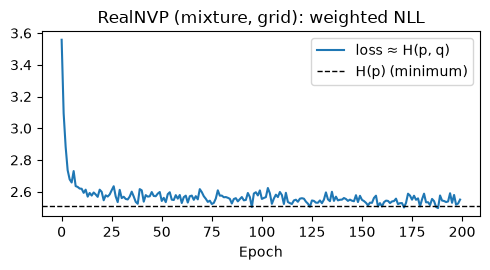

In [4]:
flow_gm = build_model("realnvp", x_dim=2, n_coupling=8)
history = fit_model(flow_gm, x_grid, log_pdf=logp_grid, epochs=200, seed=0, **FIT)
print(f"final loss {history.history['loss'][-1]:.4f} | H(p) {H_gm:.4f}  ->  KL ≈ {history.history['loss'][-1] - H_gm:.4f}")
plot_history(history, "RealNVP (mixture, grid)", entropy=H_gm)

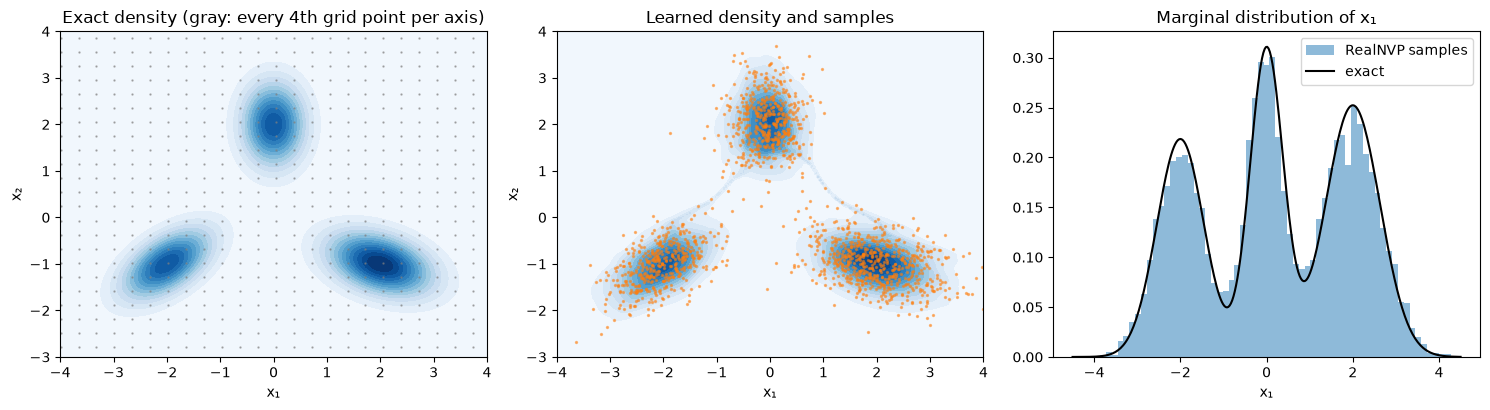

Mean log-likelihood on exact test samples: exact -2.501 | RealNVP -2.522
KL(p || q) estimate:                        0.0212
KS distance of the x₁ marginal distribution: 0.011


In [5]:
gx, gy = np.meshgrid(np.linspace(-4, 4, 200), np.linspace(-3, 4, 200))
xy_plot = np.dstack([gx, gy]).reshape(-1, 2).astype("float32")
density_exact = np.exp(mixture_logpdf(xy_plot)).reshape(gx.shape)
density_flow = np.exp(flow_gm.log_prob(xy_plot).numpy()).reshape(gx.shape)
levels = np.linspace(0, density_exact.max(), 16)
samples_gm = flow_gm.sample(10_000).numpy()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
axes[0].contourf(gx, gy, density_exact, levels=levels, cmap="Blues")
grid_sub = x_grid.reshape(120, 120, 2)[::4, ::4].reshape(-1, 2)
axes[0].scatter(grid_sub[:, 0], grid_sub[:, 1], s=0.5, color="gray", alpha=0.6)
axes[0].set(title="Exact density (gray: every 4th grid point per axis)", xlabel="x₁", ylabel="x₂", xlim=(-4, 4), ylim=(-3, 4))
axes[1].contourf(gx, gy, np.minimum(density_flow, levels[-1]), levels=levels, cmap="Blues")
axes[1].scatter(samples_gm[:1500, 0], samples_gm[:1500, 1], s=2, color="tab:orange", alpha=0.5)
axes[1].set(title="Learned density and samples", xlabel="x₁", ylabel="x₂", xlim=(-4, 4), ylim=(-3, 4))

grid1 = np.linspace(-4.5, 4.5, 300)
marg = sum(w_ * stats.norm(m[0], np.sqrt(c[0, 0])).pdf(grid1) for w_, m, c in zip(weights, means, covs))
axes[2].hist(samples_gm[:, 0], bins=60, density=True, alpha=0.5, label="RealNVP samples")
axes[2].plot(grid1, marg, "k", label="exact")
axes[2].set(title="Marginal distribution of x₁", xlabel="x₁")
axes[2].legend()
fig.tight_layout()
plt.show()

logp_exact = mixture_logpdf(x_gm_test)
logq_flow = flow_gm.log_prob(x_gm_test).numpy()
print(f"Mean log-likelihood on exact test samples: exact {logp_exact.mean():.3f} | RealNVP {logq_flow.mean():.3f}")
print(f"KL(p || q) estimate:                        {kl_estimate(logp_exact, logq_flow):.4f}")
print(f"KS distance of the x₁ marginal distribution: {ks_statistic(samples_gm[:, 0], mixture_marginal_cdf):.3f}")

**Observation:** Without a single sample, the flow reproduces the three components and their weights (KL ≈ 0.02 on exact test samples, KS of the marginal ≈ 0.01). This is the same quality as the sample-based training with 30,000 samples in the other notebook (KL ≈ 0.025). The final loss lies only ≈ 0.04 above the entropy `H(p)`, which is its theoretical minimum. As with samples, faint bridges between the modes remain, because the flow is a continuous bijection of a single Gaussian. Only about a third of the grid points carry a noticeable weight; the rest describe the (almost) empty corners of the box.

## 4. Samples vs. pdf values: number of points

For the same number of points `N`, the flow is trained once on `N` exact samples and once on a grid with `N` points.
Both runs use the same architecture and number of optimizer steps. The KL is evaluated on independent test samples.
With samples, the loss has sampling noise and the flow can overfit the finite data set. With a grid, the loss is a
quadrature, which is only accurate if the grid spacing resolves the structure of `p`.

     N | KL samples | KL pdf (grid)
  1024 |     0.2161 | 2.6074
  4096 |     0.0321 | 0.0217
 16384 |     0.0248 | 0.0376


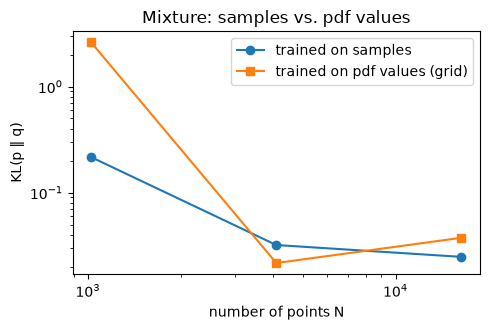

In [6]:
STEPS = 4000                  # same number of optimizer steps for every run
results = {}
for n_side in [32, 64, 128]:
    N = n_side ** 2
    pts = grid_points([-5, -4], [5, 5], n_side)
    smp = sample_mixture(N)
    bs = min(512, N)
    epochs = int(np.ceil(STEPS / np.ceil(N / bs)))
    row = {}
    for mode in ["samples", "pdf"]:
        tf.keras.utils.set_random_seed(0)
        m = build_model("realnvp", x_dim=2, n_coupling=8)
        if mode == "samples":
            fit_model(m, smp, epochs=epochs, batch_size=bs, learning_rate=2e-3, seed=0)
        else:
            fit_model(m, pts, log_pdf=mixture_logpdf(pts), epochs=epochs, batch_size=bs, learning_rate=2e-3, seed=0)
        row[mode] = kl_estimate(logp_exact, m.log_prob(x_gm_test).numpy())
    results[N] = row

print("     N | KL samples | KL pdf (grid)")
for N, r in results.items():
    print(f"{N:6d} | {r['samples']:10.4f} | {r['pdf']:.4f}")

fig, ax = plt.subplots(figsize=(5, 3.4))
Ns = list(results)
ax.loglog(Ns, [results[N]["samples"] for N in Ns], "o-", label="trained on samples")
ax.loglog(Ns, [results[N]["pdf"] for N in Ns], "s-", label="trained on pdf values (grid)")
ax.set(xlabel="number of points N", ylabel="KL(p ‖ q)", title="Mixture: samples vs. pdf values")
ax.legend()
fig.tight_layout()
plt.show()

**Observation:** With enough points, both kinds of training reach the same accuracy (KL ≈ 0.02–0.04). The remaining differences are within the noise of a short, untuned training. With very few points the two fail in different ways. 1,024 samples lead to overfitting (KL ≈ 0.2). A 32 × 32 grid (spacing ≈ 0.3, about the width of the components) fails completely (KL ≈ 2.6): the loss only sees the density **at the grid points**, and the flow is free to do anything in between. Rule of thumb: the grid spacing must be clearly finer than the smallest structure of `p`. Random points (or a grid that is shifted randomly) avoid this blind spot between fixed grid points.

## 5. RealNVP: 3D Gaussian velocity distribution

`v ~ N(0, σ² I)` with `σ = 1`; the magnitude `|v|` is Maxwell distributed. In 3D a grid is still possible, but
random points are more flexible. Two point sets with the same size (30,000) are compared:

1. **Uniform box** `v ∈ [-6, 6]³`: `r` is constant, so `w ∝ p(v)`. Most points lie in the tails and get a tiny weight.
2. **Importance sampling** from a broader Gaussian `r = N(0, 2² I)`: points are concentrated where `p` is large, and the
   placement is corrected with `log_proposal = log r(v)`. The proposal must be **wider** than `p`, otherwise the weights
   `p / r` explode in the tails.

The effective sample size `ESS = (Σw)² / Σw²` shows how many points effectively contribute.

In [7]:
sigma = 1.0
target = stats.multivariate_normal(np.zeros(3), sigma**2 * np.eye(3))
H_mw = 1.5 * np.log(2 * np.pi * np.e * sigma**2)
v_test = rng.normal(0.0, sigma, size=(10_000, 3)).astype("float32")

n_pts = 30_000
v_box = rng.uniform(-6, 6, size=(n_pts, 3)).astype("float32")
proposal = stats.multivariate_normal(np.zeros(3), 2.0**2 * np.eye(3))
v_is = proposal.rvs(n_pts, random_state=1).astype("float32")

point_sets = {
    "uniform box": dict(x=v_box, log_pdf=target.logpdf(v_box)),
    "importance sampling": dict(x=v_is, log_pdf=target.logpdf(v_is), log_proposal=proposal.logpdf(v_is)),
}
flows_mw = {}
for name, ps in point_sets.items():
    w_ = pdf_weights(log_pdf=ps["log_pdf"], log_proposal=ps.get("log_proposal"))
    ess = w_.sum() ** 2 / (w_ ** 2).sum()
    tf.keras.utils.set_random_seed(0)
    flow = build_model("realnvp", x_dim=3)
    hist = fit_model(flow, ps.pop("x"), epochs=60, seed=0, **ps, **FIT)
    flows_mw[name] = flow
    logq = flow.log_prob(v_test).numpy()
    print(f"{name:20s} | ESS {ess:7.0f} / {n_pts} | final loss {hist.history['loss'][-1]:.4f} "
          f"(H(p) = {H_mw:.4f}) | KL on test samples {kl_estimate(target.logpdf(v_test), logq):.4f}")

uniform box          | ESS     770 / 30000 | final loss 4.2813 (H(p) = 4.2568) | KL on test samples 0.0368
importance sampling  | ESS    8770 / 30000 | final loss 4.2584 (H(p) = 4.2568) | KL on test samples 0.0038


uniform box          | std per component [1.02  0.994 1.025] | KS of |v| 0.020
importance sampling  | std per component [0.976 1.02  0.995] | KS of |v| 0.010


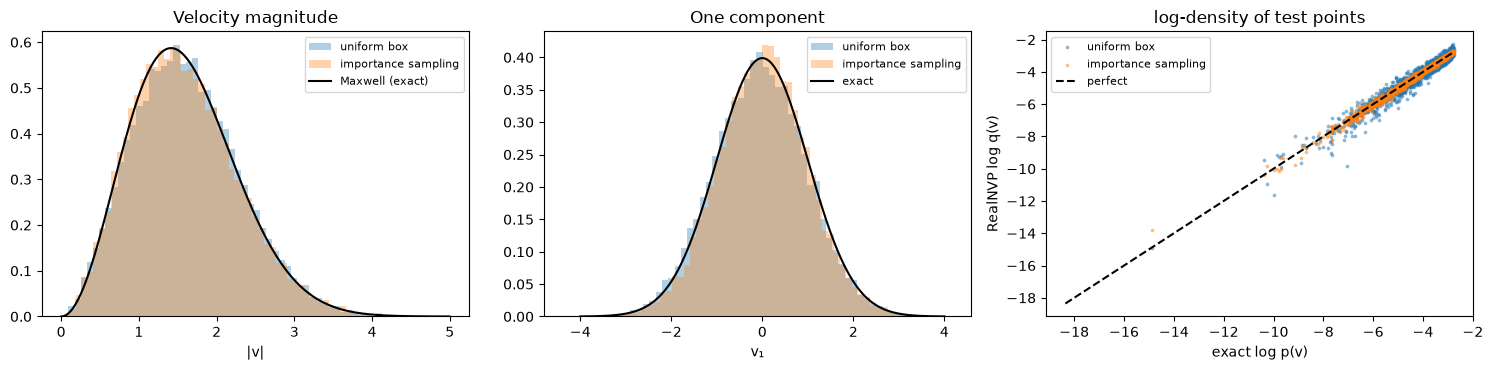

In [8]:
maxwell = stats.maxwell(scale=sigma)
vs = np.linspace(0, 5, 300)
logp_exact = target.logpdf(v_test)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for (name, flow), color in zip(flows_mw.items(), ["tab:blue", "tab:orange"]):
    s = flow.sample(20_000).numpy()
    speed = np.linalg.norm(s, axis=1)
    axes[0].hist(speed, bins=60, density=True, alpha=0.35, color=color, label=name)
    axes[1].hist(s[:, 0], bins=60, density=True, alpha=0.35, color=color, label=name)
    axes[2].scatter(logp_exact[:2000], flow.log_prob(v_test[:2000]).numpy(), s=3, alpha=0.4, color=color, label=name)
    print(f"{name:20s} | std per component {s.std(0).round(3)} | KS of |v| {ks_statistic(speed, maxwell.cdf):.3f}")
axes[0].plot(vs, maxwell.pdf(vs), "k", label="Maxwell (exact)")
axes[0].set(title="Velocity magnitude", xlabel="|v|")
v_axis = np.linspace(-4, 4, 300)
axes[1].plot(v_axis, stats.norm(0, sigma).pdf(v_axis), "k", label="exact")
axes[1].set(title="One component", xlabel="v₁")
lims = [logp_exact.min(), logp_exact.max()]
axes[2].plot(lims, lims, "k--", label="perfect")
axes[2].set(title="log-density of test points", xlabel="exact log p(v)", ylabel="RealNVP log q(v)")
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

**Observation:** Both point sets learn the Gaussian, but importance sampling is clearly better (KL ≈ 0.004 vs. 0.037, KS of `|v|` 0.010 vs. 0.020). In the uniform box only ≈ 770 of 30,000 points effectively contribute (ESS ≈ 2.5 %), so the flow effectively learns from very few points. With the broader Gaussian proposal the ESS is ≈ 30 %, and the result is as good as the sample-based training (KL ≈ 0.003). The loss of the IS run converges to the entropy `H(p) = 4.257`.

## 6. cRealNVP: temperature-dependent Maxwell distribution `p(v | T)`

The condition is the temperature `T ∈ [0.5, 2]`. For every training point a temperature is drawn, and the velocity is
drawn from a proposal that **scales with the thermal width**, `r(v | T) = N(0, 4T·I)` (twice as wide as the target).
The placement density depends on `T`, so it must be passed as `log_proposal = log r(v | T)`. The target `log p(v | T)` is
normalized for every `T` (see the docstring of `pdf_weights`).

A uniform box would also work in principle, but as in Section 5 most points would get a negligible weight, and the flow
overfits the few points that carry the weight.

ESS 17347 / 60000


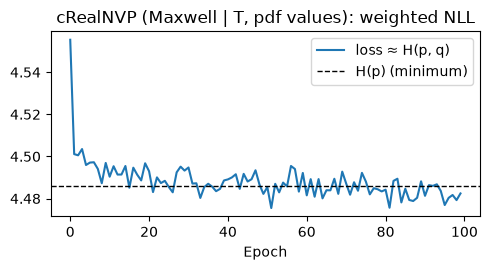

final loss 4.4824 | mean H(p(·|T)) 4.4859


In [9]:
n = 60_000
T_pts = rng.uniform(0.5, 2.0, size=(n, 1)).astype("float32")
v_pts = (rng.standard_normal((n, 3)) * 2.0 * np.sqrt(T_pts)).astype("float32")     # v ~ r(v | T) = N(0, 4T·I)


def log_maxwell_3d(v, T):
    # log N(v; 0, T·I), normalized in v for every T
    return -0.5 * (v**2).sum(axis=1) / T[:, 0] - 1.5 * np.log(2 * np.pi * T[:, 0])


log_r = log_maxwell_3d(v_pts, 4.0 * T_pts)            # log r(v | T): the same Gaussian with temperature 4T
w_ = pdf_weights(log_pdf=log_maxwell_3d(v_pts, T_pts), log_proposal=log_r)
print(f"ESS {w_.sum() ** 2 / (w_ ** 2).sum():.0f} / {n}")

crealnvp = build_model("crealnvp", x_dim=3, cond_dim=1)
history = fit_model(crealnvp, v_pts, T_pts, log_pdf=log_maxwell_3d(v_pts, T_pts), log_proposal=log_r,
                    epochs=100, seed=0, **FIT)
H_T = np.mean(1.5 * np.log(2 * np.pi * np.e * T_pts[:, 0]))      # entropy averaged over the condition
plot_history(history, "cRealNVP (Maxwell | T, pdf values)", entropy=H_T)
print(f"final loss {history.history['loss'][-1]:.4f} | mean H(p(·|T)) {H_T:.4f}")

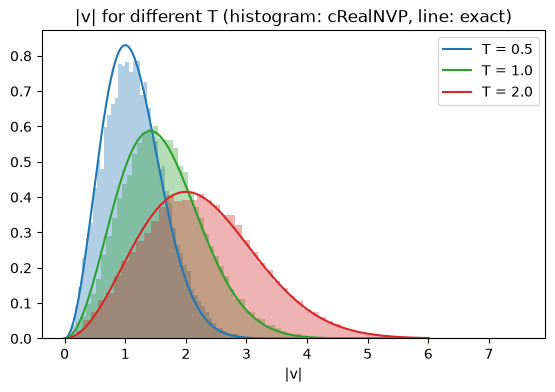

 T  | σ_samples/σ_exact | KS distance | KL(p || q)
0.5 |             1.042 |       0.042 | 0.0223
1.0 |             1.030 |       0.035 | 0.0107
2.0 |             1.011 |       0.018 | 0.0099


In [10]:
temps = np.array([[0.5], [1.0], [2.0]], dtype="float32")
samples_T = crealnvp.sample(20_000, cond=temps).numpy()

fig, ax = plt.subplots(figsize=(6.5, 4))
vs = np.linspace(0, 6, 300)
rows = []
for T, s, color in zip(temps[:, 0], samples_T, ["tab:blue", "tab:green", "tab:red"]):
    sp = np.linalg.norm(s, axis=1)
    exact = stats.maxwell(scale=np.sqrt(T))
    ax.hist(sp, bins=60, density=True, alpha=0.35, color=color)
    ax.plot(vs, exact.pdf(vs), color=color, label=f"T = {T:.1f}")
    v_T = (rng.standard_normal((10_000, 3)) * np.sqrt(T)).astype("float32")
    T_col = np.full((len(v_T), 1), T, dtype="float32")
    logq = crealnvp.log_prob(v_T, T_col).numpy()
    rows.append((T, s.std(0).mean() / np.sqrt(T), ks_statistic(sp, exact.cdf), kl_estimate(log_maxwell_3d(v_T, T_col), logq)))
ax.set(title="|v| for different T (histogram: cRealNVP, line: exact)", xlabel="|v|")
ax.legend()
plt.show()

print(" T  | σ_samples/σ_exact | KS distance | KL(p || q)")
for T, ratio, ks, kl in rows:
    print(f"{T:.1f} | {ratio:17.3f} | {ks:11.3f} | {kl:.4f}")

**Observation:** A single conditional flow, trained only on density values, covers all temperatures (KL ≈ 0.01–0.02, width within ≈ 4 %), about as well as the sample-based cRealNVP (KL ≈ 0.01–0.02). As before, the largest deviation occurs at the edge of the training range (`T = 0.5`). The `T`-dependent `log_proposal` is essential: the placement density of a scaled proposal changes by a factor `(4)^{3/2} = 8` over the range of `T`. Without it, the conditions would get systematically wrong weights.

## 7. RealNVP: unnormalized, tabulated distribution

In practice, the distribution function is often only available as a **table**, for example from a simulation or
an experiment, and its normalization is unknown. As an example, a ring distribution with a direction-dependent intensity is used:

```
p̃(x) = (1 + 0.8 cos φ) · exp(-(|x| - 2)² / (2 · 0.25²))        (unnormalized)
```

The flow is trained directly on the table values `pdf=` (not `log_pdf`). Because no exact samples exist,
the KL is evaluated by **quadrature on a fine grid**, with `p̃` normalized numerically.

KL(p || q) by quadrature: 0.0151 | mass of q inside the box: 1.0000
final loss 2.4151 | H(p) 2.3868


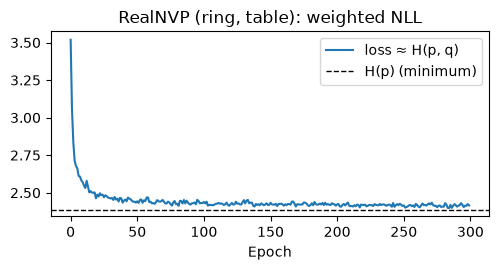

In [11]:
def ring_pdf(x):
    r, phi = np.linalg.norm(x, axis=1), np.arctan2(x[:, 1], x[:, 0])
    return (1 + 0.8 * np.cos(phi)) * np.exp(-0.5 * ((r - 2.0) / 0.25) ** 2)


# "table": values on a 100 x 100 grid, unknown normalization
x_tab = grid_points([-3.5, -3.5], [3.5, 3.5], 100)
pdf_tab = 17.3 * ring_pdf(x_tab)                  # arbitrary factor: the normalization does not matter

flow_ring = build_model("realnvp", x_dim=2, n_coupling=10)
history = fit_model(flow_ring, x_tab, pdf=pdf_tab, epochs=300, seed=0, **FIT)

# evaluation by quadrature on a finer grid
x_fine = grid_points([-3.5, -3.5], [3.5, 3.5], 300)
dA = (7.0 / 299) ** 2
p_fine = ring_pdf(x_fine)
p_fine /= p_fine.sum() * dA                       # numerically normalized
logq_fine = flow_ring.log_prob(x_fine).numpy()
mask = p_fine > 0
kl_ring = float(np.sum(p_fine[mask] * (np.log(p_fine[mask]) - logq_fine[mask])) * dA)
mass_q = float(np.exp(logq_fine).sum() * dA)
H_ring = float(-np.sum(p_fine[mask] * np.log(p_fine[mask])) * dA)
print(f"KL(p || q) by quadrature: {kl_ring:.4f} | mass of q inside the box: {mass_q:.4f}")
print(f"final loss {history.history['loss'][-1]:.4f} | H(p) {H_ring:.4f}")
plot_history(history, "RealNVP (ring, table)", entropy=H_ring)

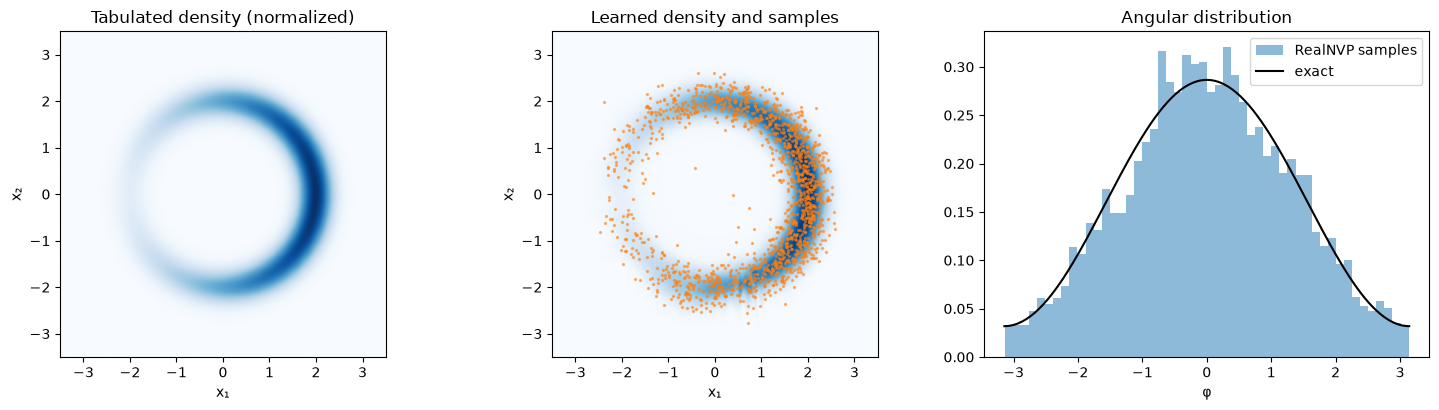

In [12]:
side = 300
P = p_fine.reshape(side, side)
Q = np.exp(logq_fine).reshape(side, side)
s_ring = flow_ring.sample(5000).numpy()
ext = [-3.5, 3.5, -3.5, 3.5]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
axes[0].imshow(P.T, origin="lower", extent=ext, cmap="Blues")
axes[0].set(title="Tabulated density (normalized)", xlabel="x₁", ylabel="x₂")
axes[1].imshow(np.minimum(Q, P.max()).T, origin="lower", extent=ext, cmap="Blues")
axes[1].scatter(s_ring[:1500, 0], s_ring[:1500, 1], s=2, color="tab:orange", alpha=0.5)
axes[1].set(title="Learned density and samples", xlabel="x₁", ylabel="x₂", xlim=ext[:2], ylim=ext[2:])

phi_s = np.arctan2(s_ring[:, 1], s_ring[:, 0])
phis = np.linspace(-np.pi, np.pi, 200)
axes[2].hist(phi_s, bins=50, density=True, alpha=0.5, label="RealNVP samples")
axes[2].plot(phis, (1 + 0.8 * np.cos(phis)) / (2 * np.pi), "k", label="exact")
axes[2].set(title="Angular distribution", xlabel="φ")
axes[2].legend()
fig.tight_layout()
plt.show()

**Observation:** The flow learns the ring and the angular modulation from 10,000 table values with an unknown normalization (KL ≈ 0.015 by quadrature, the mass of `q` inside the box ≈ 1). A ring is topologically difficult for a flow, because it has to bend a single Gaussian into a ring. The remaining error is mostly a thin bridge across the low-intensity side (φ ≈ ±π) and slightly too wide samples there. More coupling layers or longer training reduce it.

## 8. Summary and limitations

- `fit_model(..., pdf=... | log_pdf=..., log_proposal=...)` trains RealNVP / cRealNVP on density values. The loss is a weighted
  NLL and estimates the cross entropy `H(p, q)`, so `loss - H(p)` is the KL directly.
- The **normalization** of the target is not needed (Section 7). For conditional targets, the constant must not
  depend on the condition, and a condition-dependent point placement must be passed as `log_proposal` (Section 6).
- **The box / proposal must cover the support.** Mass of `p` outside the points is invisible to the loss, and the flow is not
  penalized there.
- **Dimension:** grids grow as `n^d` and uniform boxes waste most points on the tails (low ESS, Section 5). From about 3–4 dimensions on,
  importance sampling with a proposal that is broader than `p` (or the flow itself from an earlier training stage) is the better choice.
- Points with very large weights dominate the gradient. A smooth proposal that is close to `p` keeps the weights balanced.
- Discrete distributions (e.g. occupations of electronic levels) cannot be learned by a RealNVP directly.